---
title: "Figures: The Fisher Two-Period Optimal Consumption Problem"
execute:
  depends_on_env: [IC_EXEC_ENV]
---

Run this notebook in your browser, with nothing to install, in [JupyterLite](https://intertemporal-choice.github.io/lite/notebooks/index.html?path=Fisher2Period.ipynb); or open it in [Colab](https://colab.research.google.com/github/intertemporal-choice/intertemporal-choice.github.io/blob/main/content/consumption/Fisher2Period/Fisher2Period.ipynb) or [Binder](https://mybinder.org/v2/gh/intertemporal-choice/intertemporal-choice.github.io/main?labpath=content/consumption/Fisher2Period/Fisher2Period.ipynb).

The consumer has CRRA utility $\mathrm{u}(c) = c^{1-\rho}/(1-\rho)$, bank balances $b_{1}$, income $y_{1}$ and $y_{2}$ in the two periods, and the interest factor $\mathsf{R}$. Human wealth is $h_{1} = y_{1} + y_{2}/\mathsf{R}$, and consumption is

$$
c_{1} = \frac{b_{1} + h_{1}}{1 + \mathsf{R}^{-1}(\mathsf{R}\beta)^{1/\rho}}, \qquad c_{2} = (\mathsf{R}\beta)^{1/\rho} c_{1}.
$$

When the interest factor rises, the move from $A$, the choice at the old factor, to $C$, the choice at the new one, splits into three effects:

- the human wealth effect, $A \to D$: $D$ is the choice at the old factor with the human wealth the new factor leaves;
- the income effect, $D \to B$: $B$ is the choice at the old factor with just enough wealth to reach $C$'s indifference curve;
- the substitution effect, $B \to C$, along that indifference curve.

With all income in the first period, human wealth does not depend on the interest factor: $D$ is $A$, and only the income and substitution effects remain.

In [ ]:
# Run anywhere: install the book's package (it brings econ-ark, numpy and matplotlib) if it
# is missing. Inside the book's own environment this does nothing.
try:
    import intertemporal_choice
except ImportError:
    %pip install -q git+https://github.com/intertemporal-choice/intertemporal-choice.github.io

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from intertemporal_choice import style

style.use_book_style()

## The consumer's choices

`choice` is the consumption function above, and `effects` finds the four points.

In [ ]:
def u(c, rho):
    """CRRA utility, logarithmic when rho is one."""
    return np.log(c) if abs(rho - 1) < 1e-9 else c ** (1 - rho) / (1 - rho)


def u_inverse(v, rho):
    """The consumption that gives utility v."""
    return np.exp(v) if abs(rho - 1) < 1e-9 else ((1 - rho) * v) ** (1 / (1 - rho))


def choice(wealth, R, beta, rho):
    """The optimal (c1, c2) for total wealth b1 + h1, with c2 = (R beta)^(1/rho) c1 from the Euler equation."""
    growth = (R * beta) ** (1 / rho)
    c1 = wealth / (1 + growth / R)
    return np.array([c1, growth * c1])


def value(c, beta, rho):
    return u(c[0], rho) + beta * u(c[1], rho)


def effects(b1, y1, y2, R_old, R_new, beta, rho):
    """The chapter's points A, D, B and C when the interest factor moves from R_old to R_new."""
    A = choice(b1 + y1 + y2 / R_old, R_old, beta, rho)
    C = choice(b1 + y1 + y2 / R_new, R_new, beta, rho)
    D = choice(b1 + y1 + y2 / R_new, R_old, beta, rho)  # the new human wealth, at the old factor
    reach = lambda wealth: value(choice(wealth, R_old, beta, rho), beta, rho) >= value(C, beta, rho)
    low, high = 0.0, 1.0
    while not reach(high):  # value rises with wealth: bracket B's wealth, then halve the bracket
        high *= 2
    for _ in range(60):
        middle = (low + high) / 2
        low, high = (low, middle) if reach(middle) else (middle, high)
    B = choice(high, R_old, beta, rho)
    return dict(A=A, D=D, B=B, C=C)

## The figure

Each panel shows the budget constraints at the old and the new interest factor, the indifference curves through the points, the lines at the old factor through $D$ and $B$, and the size of each effect on $c_{1}$.

In [ ]:
def draw(ax, b1, y1, y2, R_old, R_new, beta, rho):
    """One panel of the chapter's figure."""
    points = effects(b1, y1, y2, R_old, R_new, beta, rho)
    A, D, B, C = (points[k] for k in "ADBC")
    width = 1.1 * max(b1 + y1 + y2 / R_old, b1 + y1 + y2 / R_new)
    height = 1.1 * max((b1 + y1) * R + y2 for R in (R_old, R_new))
    for R, wealth, line in ((R_old, b1 + y1 + y2 / R_old, "-"), (R_new, b1 + y1 + y2 / R_new, "--")):
        ax.plot([0, wealth], [R * wealth, 0], "k" + line, lw=1.1, label=f"R = {R:.2f}")
    for P in (D, B):  # at the old factor, through D and B
        wealth = P[0] + P[1] / R_old
        ax.plot([0, wealth], [R_old * wealth, 0], ":", color="0.45", lw=1.0)
    same = np.allclose(D, A)  # all income in the first period: no human wealth effect
    for P in (A, C) if same else (A, D, C):  # indifference curves, near each point
        c1 = np.linspace(0.45 * P[0], min(2.2 * P[0], width), 200)
        with np.errstate(all="ignore"):
            c2 = u_inverse((value(P, beta, rho) - u(c1, rho)) / beta, rho)
        c2 = np.where(np.isfinite(c2) & (c2 > 0) & (c2 < 2 * height), c2, np.nan)  # the curve's visible branch
        ax.plot(c1, c2, color="C0", lw=1.0)
    if not same:  # the fall in human wealth, on the horizontal axis
        ends = sorted(b1 + y1 + y2 / R for R in (R_old, R_new))
        ax.annotate("", xy=(ends[0], 0.03 * height), xytext=(ends[1], 0.03 * height),
                    arrowprops=dict(arrowstyle="<->", lw=0.9))
        ax.text(sum(ends) / 2, 0.05 * height, "$\\Delta h$", ha="center", va="bottom")
    for name, P in points.items():
        if name == "D" and same:
            continue
        ax.plot(*P, "o", color="black", ms=4)
        ax.annotate(name, P, xytext=(5, 5), textcoords="offset points")
    rows = [("human wealth", "A", "D"), ("income", "D", "B"), ("substitution", "B", "C"), ("total", "A", "C")]
    if same:
        rows = [("income", "A", "B")] + rows[2:]
    text = "\n".join(f"{what} effect {a}{b}: {points[b][0] - points[a][0]:+.3f}" for what, a, b in rows)
    ax.text(0.97, 0.97, f"$(y_1, y_2) = ({y1:g}, {y2:g})$\neffects on $c_1$:\n" + text,
            transform=ax.transAxes, ha="right", va="top", fontsize=9)
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xlabel("$c_1$", loc="right")
    ax.set_ylabel("$c_2$", loc="top", rotation=0)
    ax.legend(loc="lower left", fontsize=9)

The interest factor rises from one to two, with all income in the first period (top) and all in the second (bottom).

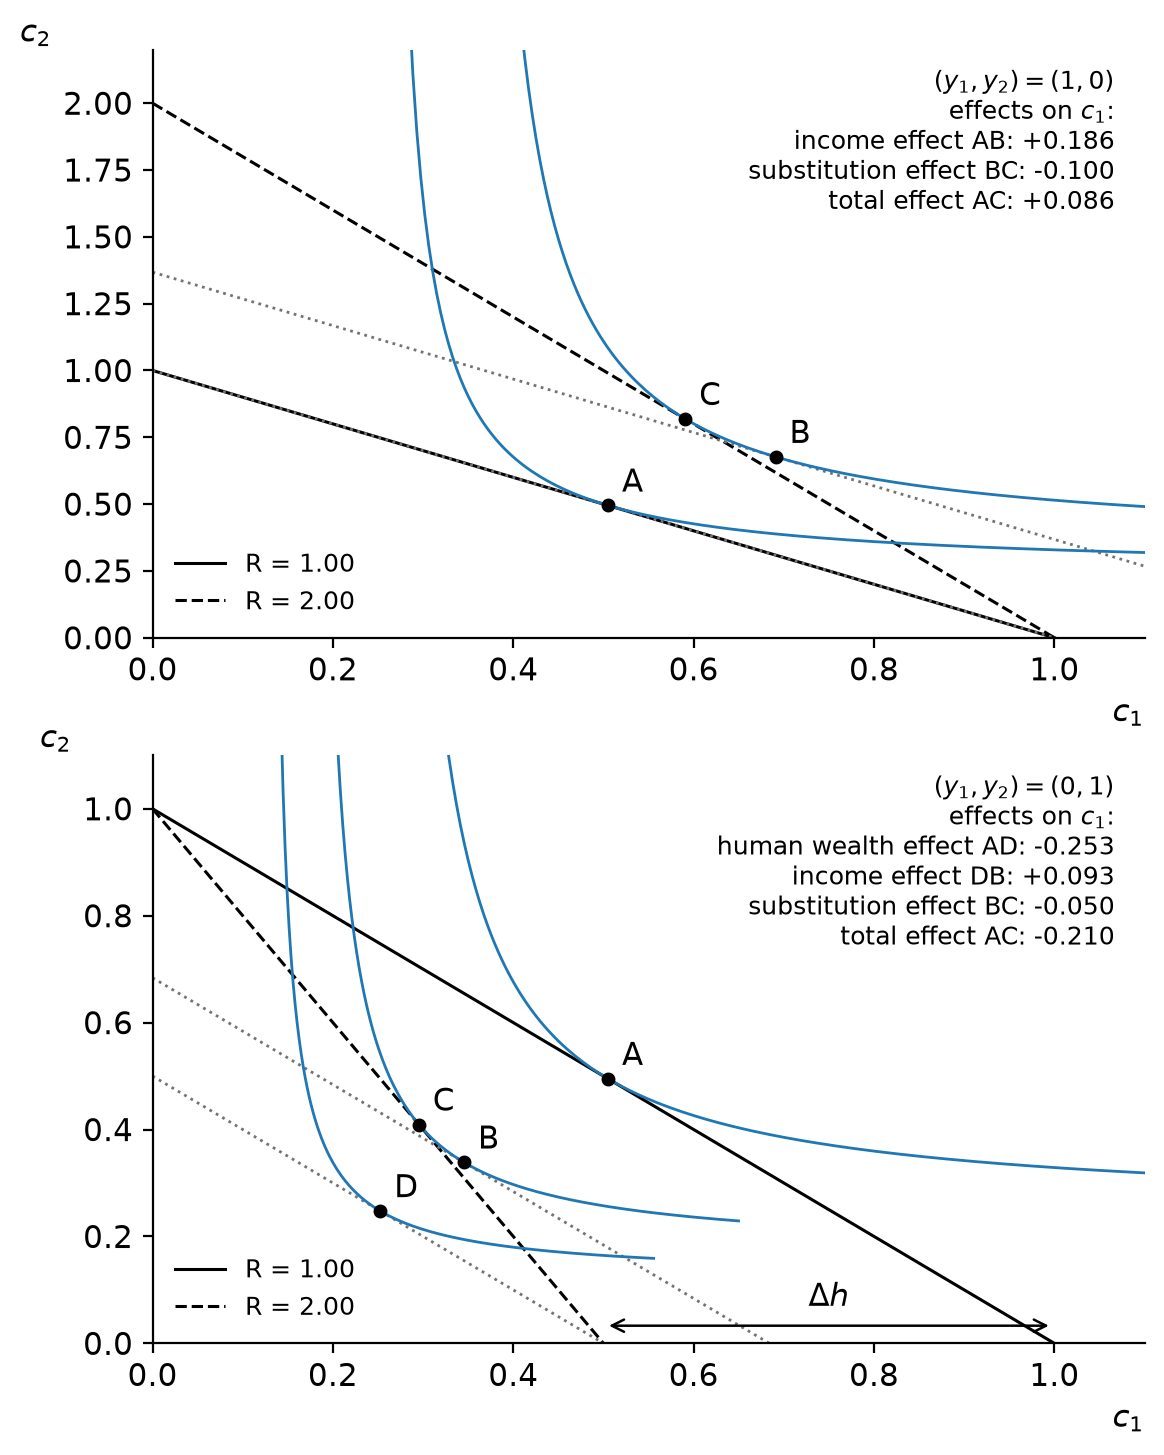

In [ ]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.4, 8.4))
draw(top, b1=0, y1=1, y2=0, R_old=1.0, R_new=2.0, beta=0.96, rho=2)
draw(bottom, b1=0, y1=0, y2=1, R_old=1.0, R_new=2.0, beta=0.96, rho=2)
style.save(fig, "FisherFigure")

## With sliders

With relative risk aversion above one, the income effect on $c_{1}$ outweighs the substitution effect; below one, the substitution effect does.

In [ ]:
def explore(b1, y1, y2, R_old, R_new, beta, rho):
    fig, ax = plt.subplots(figsize=(6.4, 5.0))
    draw(ax, b1, y1, y2, R_old, R_new, beta, rho)
    plt.show()


slider = lambda value, low, high, step, label: widgets.FloatSlider(
    value=value, min=low, max=high, step=step, description=label, continuous_update=False)
widgets.interact(
    explore,
    b1=slider(0.0, 0.0, 1.0, 0.05, "b₁"),
    y1=slider(0.0, 0.0, 1.0, 0.05, "y₁"),
    y2=slider(1.0, 0.0, 1.0, 0.05, "y₂"),
    R_old=slider(1.0, 0.5, 3.0, 0.05, "R before"),
    R_new=slider(2.0, 0.5, 3.0, 0.05, "R after"),
    beta=slider(0.96, 0.5, 1.0, 0.01, "β"),
    rho=slider(2.0, 0.5, 5.0, 0.1, "ρ"),
);

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='b₁', max=1.0, step=0.05), F…